In [1]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc

def parse_comsol_data(filepath):
    """
    Parse COMSOL data file and return organized DataFrame.
    
    Parameters:
    -----------
    filepath : str
        Path to the COMSOL data file
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with columns for coordinates, physical parameters, U_in, and Sb_option
    """
    
    with open(filepath, 'r') as file:
        lines = file.readlines()
    
    # Find the header line with column names
    header_line = None
    data_start = None
    
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break
    
    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")
    
    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix
    
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = []
    
    for col in columns:
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            
            # Extract U_in value
            u_in_match = re.search(r'U_in=([0-9E.-]+)', conditions)
            u_in = float(u_in_match.group(1)) if u_in_match else None
            
            # Extract Sb_option value
            sb_match = re.search(r'Sb_option=([0-9]+)', conditions)
            sb_option = int(sb_match.group(1)) if sb_match else None
            
            parsed_columns.append({
                'original_name': col,
                'param_name': param_name,
                'u_in': u_in,
                'sb_option': sb_option
            })
        else:
            # Coordinate columns (r, z)
            parsed_columns.append({
                'original_name': col,
                'param_name': col,
                'u_in': None,
                'sb_option': None
            })
    
    # Read the data
    data_lines = lines[data_start:]
    
    # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    
    # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=[col['original_name'] for col in parsed_columns])
    
    # Reorganize data by grouping parameters by U_in and Sb_option
    organized_data = []
    
    # Get coordinate columns (r, z)
    coord_cols = [col for col in parsed_columns if col['u_in'] is None]
    
    # Get unique combinations of U_in and Sb_option
    param_cols = [col for col in parsed_columns if col['u_in'] is not None]
    unique_conditions = set((col['u_in'], col['sb_option']) for col in param_cols)
    
    for u_in, sb_option in unique_conditions:
        # Get all parameter columns for this condition
        condition_cols = [col for col in param_cols 
                         if col['u_in'] == u_in and col['sb_option'] == sb_option]
        
        # For each row in the original data
        for idx, row in df_raw.iterrows():
            # Start with coordinates
            row_data = {'r': row[coord_cols[0]['original_name']], 
                       'z': row[coord_cols[1]['original_name']]}
            
            # Add condition identifiers
            row_data['U_in'] = u_in
            row_data['Sb_option'] = sb_option
            
            # Add all parameters for this condition
            for col in condition_cols:
                param_name = col['param_name']
                # Clean up parameter names (remove units and extra info)
                clean_param_name = param_name.split('(')[0].strip()
                row_data[clean_param_name] = row[col['original_name']]
            
            organized_data.append(row_data)
    
    # Create the final organized DataFrame
    df_organized = pd.DataFrame(organized_data)
    
    # Sort by U_in, Sb_option, and spatial coordinates
    df_organized = df_organized.sort_values(['U_in', 'Sb_option', 'r', 'z']).reset_index(drop=True)
    
    return df_organized


def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth +2.5e6+1e5)  # Adding 2.5 MPa offset for lithostatic pressure at surface    
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy



def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['r','z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                print('loop start')
                #print(f"Processing param: {param}")
                print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    
                    r = raw_row['r']
                    z = raw_row['z']

                    output_df.at[row_idx, 'r'] = r
                    output_df.at[row_idx, 'z'] = z
                    
                    for var_name in var_names:
                        print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df


def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis





In [2]:
def plot_conduit_analysis_fig1(df,df_ge, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })

    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xc': r'$X_c$',

        'Cw': r'$C_w$ (%)',

        'mu_m': (
            r'$\eta_{\mathrm{melt}}$'
            + r'$(\mathrm{Pa\,s})$'
        ),

        'nu_c': r'$\mu_{\mathrm{crystals}}$',

        'P_excess': r'$\Delta P$ (MPa)',

        'spf.mu*spf.sr': r'$\tau_w$ (MPa)',
    }
    #+ '\n'
        
    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.oslo
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.2), oslo_cmap(0.5), oslo_cmap(0.8)]
    sb_labels = {0: '100% Gas Loss', 2: 'Step Gas Loss at 100 m', 3: 'Ramped Gas Loss'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(n_sb_options + 1, n_vars, height_ratios=[0.8] + [1.2]*n_sb_options, 
                         hspace=0.6, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    for i in range(n_sb_options):
        row_axes = []
        for j in range(n_vars):
            # Now, main grid starts at row 1 (since row 0 is the top plot)
            if i == 0:
                ax = fig.add_subplot(gs[i + 1, j])
            else:
                ax = fig.add_subplot(gs[i + 1, j], sharex=main_axes[0][j])
            row_axes.append(ax)
        main_axes.append(row_axes)
    # Plot main data
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        
        for j, (var, var_name) in enumerate(variables.items()):
            ax = main_axes[i][j]
            
            # Special handling for 1-Sb - plot in same colors as bottom row
            if var == '1-Sb':
                for velocity in velocities:
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=0.6, alpha=0.75)
            else:
                # Plot other variables with colormap
                for velocity in velocities:
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    
                    if not data_subset.empty and var in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        
                        # Get color based on velocity using log scale
                        color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                        color = cmap(color_index)
                        if var in ['spf.mu*spf.sr', 'P_excess']:
                            plot_vals = data_subset[var] / 1e6
                            x_label = var_name.replace('(Pa)', '(MPa)')
                        elif var == 'Cw':
                            plot_vals = data_subset[var] * 100  # Convert to wt%
                            

                        else:
                            plot_vals = data_subset[var]
                            x_label = var_name
                        ax.plot(plot_vals, depth, color=color, linewidth=0.6, alpha=0.75)
                                    
            
                     # Set logarithmic scale for shear stress and magma viscosity only
            if var in ['spf.mu*spf.sr', 'mu_mbc','mu_m','nu_c']:
                ax.set_xscale('log')
            if ax.get_xscale() == 'log':
                pass
            else:
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
            
            if var == 'Cw':
                ax.set_xticks([0, 1, 2, 3])
                ax.set_xticklabels(['0', '1', '2', '3'])
            elif var == 'spf.mu*spf.sr':
                ticks = [1e-6, 1e-3, 1e0]
                ax.set_xticks(ticks)
                ax.set_xticklabels([r'$10^{-6}$', r'', r'$10^{0}$'])
            elif var == 'nu_c':
                ticks = [1, 1e2, 1e4]
                ax.set_xticks(ticks)
                ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
            elif var == 'Xc':
                ticks = [0.25, 0.5, 0.75]
                ax.set_xticks(ticks)
                ax.set_xticklabels([r'$0.25$', r'$0.5$', r'$0.75$'])
            elif var == 'mu_m':
                ticks = [1e4, 1e5, 1e6]
                ax.set_xticks(ticks)
                ax.set_xticklabels([r'$10^{4}$', r'$10^{5}$', r'$10^{6}$'])
            # Reverse y-axis (depth increases downward)
            #ax.invert_yaxis()
            
            # Set labels and formatting
            # Always show x-axis labels and ticks, even for shared x-axes
            ax.set_xlabel(var_name,labelpad=1)
            ax.tick_params(axis='x', labelbottom=True)
            if j == 0:  # Left column
                ax.set_ylabel(f"Depth (m)")#\n{sb_labels.get(sb_option, f'{sb_option}')}")
            else:
                ax.set_ylabel("")
                # Hide y-tick labels for non-leftmost plots
                ax.set_yticklabels([])
            
            ax.grid(True, alpha=0.3)
            
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    

  



    bottom_row = len(main_axes) - 1
    for j, ax in enumerate(main_axes[bottom_row]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        
        # Add a shared y-label for the bottom row (centered vertically)
        #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)

        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[bottom_row]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # Add colorbar to the right of the main plots, but not spanning the bottom row
    cbar_ax = fig.add_axes([0.92, 0.1, 0.02, 0.45])  # [left, bottom, width, height]
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')
    #cbar.set_label('Ascent Velocity (m/s)', rotation=270, labelpad=20)
    


    specific_velocities = [1, 0.1, 1e-2, 1e-3, 1e-4, 1e-5]

    # Use np.isclose rather than exact float xcomparison.
    available_velocities = [
        value
        for value in specific_velocities
        if np.any(np.isclose(velocities, value))
    ]

    tick_labels = []
    for value in available_velocities:
        if value == 1:
            tick_labels.append(r"$1$ m/s")
        elif value == 0.1:
            tick_labels.append(r"$0.1$ m/s")
        else:
            exponent = int(np.log10(value))
            tick_labels.append(rf"$10^{{{exponent}}}$ m/s")

    cbar.set_ticks(available_velocities)
    cbar.set_ticklabels(tick_labels)
    
    # Create top subplot spanning the full width
    top_ax = fig.add_subplot(gs[0, :])
    station_distance = 250  # meters

    param_def = 1  # assuming param_def=1 
    top_ax2 = top_ax.twinx()
    top_ax2.spines['right'].set_color('red')
    top_ax2.tick_params(axis='y', colors='red')
    top_ax2.yaxis.label.set_color('red')
    top_ax2.set_ylabel('Tilt at 250 m \n (µrad)', color='red',labelpad=1)
    #top_ax2.set_zorder(1)  # Drawn first (behind)
    #top_ax.set_zorder(2) 
    x = df_ge[(df_ge['Sb_option'] == 0)&(df_ge['r']==station_distance)&(df_ge['param_def']==1)]['U_in']
    disp_var='solid.RotrZ'
    
    y = df_ge[(df_ge['Sb_option'] == 0)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e6
    
    top_ax2.semilogx(x, y, color='r', linestyle='--', linewidth=0.75, label='Tilt at 250 m')

    # Plot P_excess at deepest depth vs U_in for each Sb_option
    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []


    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6

        
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color='gray', alpha=0.8, linewidth=1)
        for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            print(c)
            top_ax.semilogx(v, p, marker='o', color=c, markersize=4, linewidth=0)       
        
        # Add another y axis to the top_ax showing tilt against velocity at r = 250 m
        # Assuming df_ge has columns 'r', 'z', 'U_in', 'tilt'
      
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        )

    top_ax.set_xlabel('Inlet Velocity (m/s)', labelpad=0.2)
    top_ax.set_ylabel(r'Inlet $\Delta P$ (MPa)')
    top_ax.set_title('Effect of Syn-eruptive Crystalisation')
    top_ax.grid(True, alpha=0.3)

 
    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right'
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...
    for i, row_axes in enumerate(main_axes):
        for j, ax in enumerate(row_axes):
            ax.text(
                0.98, 0.02, labels[label_idx],
                transform=ax.transAxes,
                fontsize=10,
                fontweight='bold',
                va='bottom', ha='right'
            )
            label_idx += 1

    fig.savefig(f'../../output_plots/2/figure1_conduit_analysis_{colormap}_Colima_with_tilt_signal.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'../../output_plots/2/figure1_conduit_analysis_{colormap}_Colima_with_tilt_signal.pdf', dpi=300, bbox_inches='tight')

    return fig



In [3]:
# File path
filepath_flow = '../../data/2_Xc_growth/conduit_wall_Xc_growth.txt'


# Load and organize the data
print("Loading COMSOL conduit data...")
df = parse_comsol_data(filepath_flow)




Loading COMSOL conduit data...


In [4]:
df

,r,z,U_in,Sb_option,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,rho_m,Xm,T,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw
0,15.0,-2895.466455,0.00001,0,0.404593,0.404593,0.0,0.0,4.143631e-01,2700.0,2700.0,0.595407,1223.0,8.331213e+07,3.296130e+04,1.0,4.714759,1.554046e+05,0.000010,0.030000
1,15.0,-2886.777268,0.00001,0,0.404996,0.404996,0.0,0.0,4.153289e-01,2700.0,2700.0,0.595004,1223.0,8.308198e+07,3.296130e+04,1.0,4.725796,1.557684e+05,0.000010,0.030000
2,15.0,-2879.160042,0.00001,0,0.405351,0.405351,0.0,0.0,4.161789e-01,2700.0,2700.0,0.594649,1223.0,8.288022e+07,3.296130e+04,1.0,4.735525,1.560891e+05,0.000010,0.030000
3,15.0,-2878.132411,0.00001,0,0.405399,0.405399,0.0,0.0,4.162944e-01,2700.0,2700.0,0.594601,1223.0,8.285300e+07,3.296130e+04,1.0,4.736842,1.561324e+05,0.000010,0.030000
4,15.0,-2876.585622,0.00001,0,0.405471,0.405471,0.0,0.0,4.164665e-01,2700.0,2700.0,0.594529,1223.0,8.281203e+07,3.296130e+04,1.0,4.738825,1.561978e+05,0.000010,0.030000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
258791,15.0,-3.482659,0.31623,0,0.418389,0.418389,0.0,0.0,3.605186e+06,2700.0,2700.0,0.581611,1223.0,4.112422e+06,1.205069e+07,1.0,5.115223,6.164199e+07,0.308110,0.002622
258792,15.0,-2.432795,0.31623,0,0.418419,0.418419,0.0,0.0,3.565946e+06,2700.0,2700.0,0.581581,1223.0,3.611223e+06,1.222250e+07,1.0,5.116142,6.253205e+07,0.307900,0.002597
258793,15.0,-2.083809,0.31623,0,0.418429,0.418429,0.0,0.0,3.552337e+06,2700.0,2700.0,0.581571,1223.0,3.450450e+06,1.226253e+07,1.0,5.116450,6.274062e+07,0.307829,0.002591
258794,15.0,-1.387282,0.31623,0,0.418449,0.418449,0.0,0.0,3.526586e+06,2700.0,2700.0,0.581551,1223.0,3.134290e+06,1.232152e+07,1.0,5.117066,6.305003e+07,0.307699,0.002583


In [5]:

filepath_edge = r'../../data/2_Xc_growth/ground_edge_Xc_growth.txt'

var_names = ['U_in', 'param_def', 'tau_Xc', 'Sb_option', 'param_1']
df_ge = parse_comsol_edge_data(filepath_edge, var_names)



['r', 'z', 'u2 (m)', 'v2 (m)', 'w2 (m)', 'solid.RotrZ (rad)', 'U_in', 'param_def', 'tau_Xc', 'Sb_option', 'param_1']
Number of rows in new dataframe
12144
Number of unique variables: (138, 5)
loop start
Processing param: u2 (m)
0 U_in
0 param_def
0 tau_Xc
0 Sb_option
0 param_1
1 U_in
1 param_def
1 tau_Xc
1 Sb_option
1 param_1
2 U_in
2 param_def
2 tau_Xc
2 Sb_option
2 param_1
3 U_in
3 param_def
3 tau_Xc
3 Sb_option
3 param_1
4 U_in
4 param_def
4 tau_Xc
4 Sb_option
4 param_1
5 U_in
5 param_def
5 tau_Xc
5 Sb_option
5 param_1
6 U_in
6 param_def
6 tau_Xc
6 Sb_option
6 param_1
7 U_in
7 param_def
7 tau_Xc
7 Sb_option
7 param_1
8 U_in
8 param_def
8 tau_Xc
8 Sb_option
8 param_1
9 U_in
9 param_def
9 tau_Xc
9 Sb_option
9 param_1
10 U_in
10 param_def
10 tau_Xc
10 Sb_option
10 param_1
11 U_in
11 param_def
11 tau_Xc
11 Sb_option
11 param_1
12 U_in
12 param_def
12 tau_Xc
12 Sb_option
12 param_1
13 U_in
13 param_def
13 tau_Xc
13 Sb_option
13 param_1
14 U_in
14 param_def
14 tau_Xc
14 Sb_option
14 param

In [6]:
# Display basic information about the dataset
print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")


# Display first few rows
print(f"\nFirst 5 rows:")
print(df.head())

# Display summary statistics
print(f"\nSummary statistics:")
print(df.describe())


Dataset loaded successfully!
Shape: (258796, 20)
Columns: ['r', 'z', 'U_in', 'Sb_option', 'Xc_nocap', 'Xc', 'Sb', 'Xg', 'spf.mu*spf.sr', 'rho_b', 'rho_m', 'Xm', 'T', 'linproj_r', 'mu_m', 'nu_b_inf', 'nu_c', 'mu_mbc', 'u_av', 'Cw']

First 5 rows:


      r            z     U_in  Sb_option  Xc_nocap        Xc   Sb   Xg  \
0  15.0 -2895.466455  0.00001          0  0.404593  0.404593  0.0  0.0   
1  15.0 -2886.777268  0.00001          0  0.404996  0.404996  0.0  0.0   
2  15.0 -2879.160042  0.00001          0  0.405351  0.405351  0.0  0.0   
3  15.0 -2878.132411  0.00001          0  0.405399  0.405399  0.0  0.0   
4  15.0 -2876.585622  0.00001          0  0.405471  0.405471  0.0  0.0   

   spf.mu*spf.sr   rho_b   rho_m        Xm       T     linproj_r  \
0       0.414363  2700.0  2700.0  0.595407  1223.0  8.331213e+07   
1       0.415329  2700.0  2700.0  0.595004  1223.0  8.308198e+07   
2       0.416179  2700.0  2700.0  0.594649  1223.0  8.288022e+07   
3       0.416294  2700.0  2700.0  0.594601  1223.0  8.285300e+07   
4       0.416466  2700.0  2700.0  0.594529  1223.0  8.281203e+07   

           mu_m  nu_b_inf      nu_c         mu_mbc     u_av    Cw  
0  32961.295979       1.0  4.714759  155404.574835  0.00001  0.03  
1  32961.2


Creating conduit analysis plot...
axes.labelsize: 11.0
axes.titlesize: 11.0
xtick.labelsize: 9.5
ytick.labelsize: 9.5
legend.fontsize: 11.0
figure.titlesize: 11.0
11.0
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 101826431.39356604
Debug: P_excess range: -422813.1895630411 to 19765431.393566042
Sb_option 0, U_in 1e-05: z=-3000.0, linproj_r=8.61e+07, P_excess=4.02e+06
Sb_option 0, U_in 1.2589e-05: z=-3000.0, linproj_r=8.66e+07, P_excess=4.49e+06
Sb_option 0, U_in 1.5849e-05: z=-3000.0, linproj_r=8.70e+07, P_excess=4.97e+06
(np.float64(0.016676), np.float64(0.020805), np.float64(0.040926), np.float64(1.0))
(np.float64(0.037988), np.float64(0.051323), np.float64(0.083044), np.float64(1.0))
(np.float64(0.060311), np.float64(0.08209), np.float64(0.123053), np.float64(1.0))
(np.float64(0.072511), np.float64(0.110663), np.float64(0.168079), np.float64(1.0))
(np.float64(0.08396), np.float64(0.13752), np.float64(0.207794), np.f

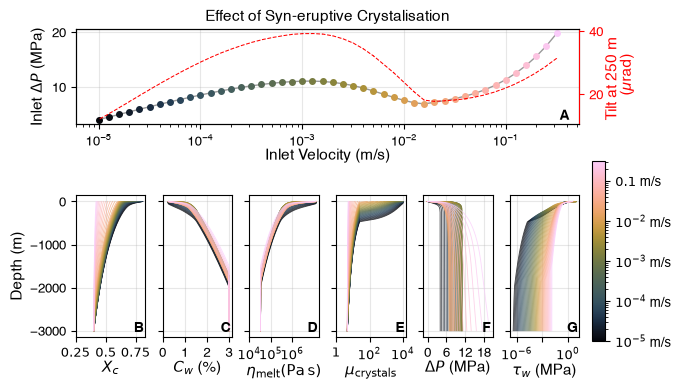

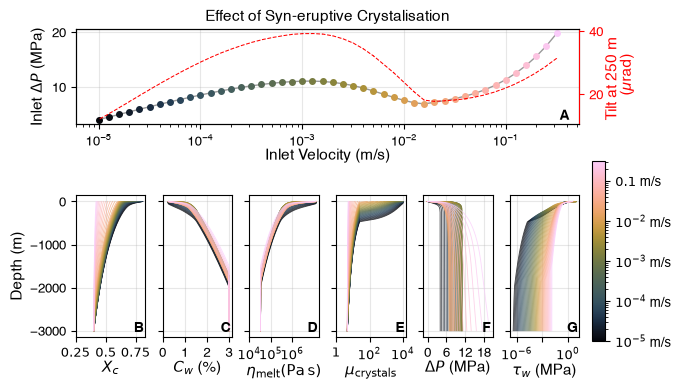

In [7]:

# Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')
plot_conduit_analysis_fig1(df, df_ge,colormap='batlowK', figsize=(6.5, 4), save_plot=True)
#plot_conduit_analysis(df, colormap='managua')


In [8]:
from matplotlib.ticker import LogLocator, MultipleLocator


def plot_conduit_analysis_fig1(
    df,
    df_ge,
    colormap='batlow',
    figsize=(18, 13),
    save_plot=True,
    profile_sb_option=0
):

    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import string

    from matplotlib.ticker import MaxNLocator
    from matplotlib.colors import LogNorm

    try:
        from cmcrameri import cm as cmc
    except ImportError:
        cmc = None

    # -------------------------------------------------------------------------
    # Plot styling
    # -------------------------------------------------------------------------
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 10,
        'figure.titlesize': 11
    })

    # -------------------------------------------------------------------------
    # Calculate excess pressure
    # -------------------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    # Allow either spelling in dataframe
    bulk_visc_candidates = ['mu_mcb', 'mu_mbc']

    bulk_visc_col = next(
        (col for col in bulk_visc_candidates if col in df_analysis.columns),
        None
    )

    if bulk_visc_col is None:
        raise KeyError(
            "Could not find magma-bubble-crystal viscosity column. "
            "Expected either 'mu_mcb' or 'mu_mbc'."
        )

    # -------------------------------------------------------------------------
    # Variables
    #
    # Row 2: crystal / melt properties
    # Row 3: deformation-source stresses
    # -------------------------------------------------------------------------
    row2_variables = {
        'Xc': r'$X_c$',
        'Cw': r'$C_w$ (%)',
        'mu_m': r'$\eta_{\mathrm{melt}}\;(\mathrm{Pa\,s})$',
        'nu_c': r'$\mu_{\mathrm{crystals}}$',
        bulk_visc_col: r'$\eta (\mathrm{Pa\,s})$'
    }

    row3_variables = {
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)'
    }

    # -------------------------------------------------------------------------
    # Sb options
    # -------------------------------------------------------------------------
    sb_options = sorted(df_analysis['Sb_option'].unique())

    if profile_sb_option not in sb_options:
        profile_sb_option = sb_options[0]

    sb_labels = {
        0: '100% Gas Loss',
        2: 'Step Gas Loss at 100 m',
        3: 'Ramped Gas Loss'
    }

    if cmc is not None:
        oslo_cmap = cmc.oslo
    else:
        oslo_cmap = plt.cm.Blues

    sb_colors = [
        oslo_cmap(0.2),
        oslo_cmap(0.5),
        oslo_cmap(0.8)
    ]

    sb_to_color = {
        sb_option: sb_colors[i % len(sb_colors)]
        for i, sb_option in enumerate(sb_options)
    }

    sb_to_label = {
        sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}')
        for sb_option in sb_options
    }

    # -------------------------------------------------------------------------
    # Velocities and colour mapping
    # -------------------------------------------------------------------------
    velocities = np.array(
        sorted(df_analysis['U_in'].dropna().unique())
    )

    log_velocities = np.log10(velocities)
    log_min = log_velocities.min()
    log_max = log_velocities.max()

    velocity_to_color = {
        velocity:
        (np.log10(velocity) - log_min) / (log_max - log_min)
        for velocity in velocities
    }

    cmap = get_colormap(colormap)

    # -------------------------------------------------------------------------
    # Figure layout
    #
    # Row 1: inlet pressure + 
    

    
    # Row 2: Xc, Cw, melt viscosity, crystal viscosity, mu_mcb
    # Row 3: excess pressure + wall shear stress
    # -------------------------------------------------------------------------
    fig = plt.figure(figsize=figsize)

    gs = fig.add_gridspec(
        3,
        10,
        height_ratios=[0.8, 1.2, 1.2],
        hspace=0.3,
        wspace=0.3
    )

    # Top row
    top_ax = fig.add_subplot(gs[0, :])

    # Second row: five panels
    row2_axes = [
        fig.add_subplot(gs[1, 0:2]),
        fig.add_subplot(gs[1, 2:4]),
        fig.add_subplot(gs[1, 4:6]),
        fig.add_subplot(gs[1, 6:8]),
        fig.add_subplot(gs[1, 8:10]),
    ]

    # Third row: two larger panels
    row3_axes = [
        fig.add_subplot(gs[2, 0:5]),
        fig.add_subplot(gs[2, 5:10]),
    ]

    # -------------------------------------------------------------------------
    # Helper function for depth-profile panels
    # -------------------------------------------------------------------------
    def plot_profile_panel(ax, var, var_name, df_filtered):

        for velocity in velocities[::2]:

            data_subset = df_filtered[
                np.isclose(df_filtered['U_in'], velocity)
            ].copy()

            if data_subset.empty or var not in data_subset.columns:
                continue

            data_subset = data_subset.sort_values('z')

            depth = data_subset['z']

            color_index = velocity_to_color[velocity]
            color = cmap(color_index)

            if var in ['spf.mu*spf.sr', 'P_excess']:

                plot_vals = data_subset[var] / 1e6

            elif var == 'Cw':

                plot_vals = data_subset[var] * 100

            else:

                plot_vals = data_subset[var]

            # if var in ['spf.mu*spf.sr', 'P_excess']:
            
            ax.plot(
                    plot_vals[::3],
                    depth[::3],
                    color=color,
                    linewidth=1.2,
                    alpha=0.8
                    )
            # else:
            #     ax.plot(
            #         plot_vals,
            #         depth,
            #         color=color,
            #         linewidth=0.7,
            #         alpha=0.8
            #     )

        # ---------------------------------------------------------------------
        # Axis scales
        # ---------------------------------------------------------------------
        if var in [
            'spf.mu*spf.sr',
            'mu_m',
            'nu_c',
            bulk_visc_col
        ]:
            ax.set_xscale('log')

        if ax.get_xscale() != 'log':
            ax.xaxis.set_major_locator(
                MaxNLocator(nbins=4, prune=None)
            )

        # ---------------------------------------------------------------------
        # Manual ticks
        # ---------------------------------------------------------------------
        if var == 'Cw':

            ax.set_xticks([0,  2, 4])
            ax.set_xticklabels(['0', '2', '4'])
            # have minor ticks every 1 wt%
            ax.xaxis.set_minor_locator(
                MaxNLocator(nbins=5, integer=True, prune=None)
            )

        elif var == 'spf.mu*spf.sr':

            ax.set_xticks([1e-6, 1e-3, 1e0])
            ax.set_xticklabels([
                r'$10^{-6}$',
                r'$10^{-3}$',
                r'$10^{0}$'
            ])
            # have minor grid ever order of magnitude
            ax.xaxis.set_minor_locator(
                LogLocator(base=10.0, subs=np.arange(1.0, 10.0) * 0.1, numticks=10)
            )

        elif var == 'nu_c':

            ax.set_xticks([1, 1e2, 1e4])
            ax.set_xticklabels([
                r'$1$',
                r'$10^{2}$',
                r'$10^{4}$'
            ])

        elif var == 'Xc':

            ax.set_xticks([0.3, 0.5, 0.7])
            ax.set_xticklabels([
                r'$0.3$',
                r'$0.5$',
                r'$0.7$',

            ])

        elif var == 'mu_m':

            ax.set_xticks([1e5, 1e6,1e7])
            ax.set_xticklabels([
                r'$10^{5}$',
                r'$10^{6}$',
                r'$10^{7}$'
            ])
        elif var == 'mu_mbc' or var == 'mu_mcb':

            ax.set_xticks([1e6,1e8,1e10])
            ax.set_xticklabels([
                r'$10^{6}$',
                r'$10^{8}$',
                r'$10^{10}$'
            ])


        ax.set_xlabel(var_name, labelpad=1)

        ax.grid(
            True,
            alpha=0.3
        )

    # -------------------------------------------------------------------------
    # Profile data
    # -------------------------------------------------------------------------
    df_profile = df_analysis[
        df_analysis['Sb_option'] == profile_sb_option
    ].copy()

    # -------------------------------------------------------------------------
    # SECOND ROW
    # Xc, Cw, eta_melt, mu_crystals, mu_mcb
    # -------------------------------------------------------------------------
    for j, ((var, var_name), ax) in enumerate(
        zip(row2_variables.items(), row2_axes)
    ):

        plot_profile_panel(
            ax,
            var,
            var_name,
            df_profile
        )

        if j == 0:
            ax.set_ylabel('z (m)')
        else:
            ax.set_ylabel('')
            ax.tick_params(
                axis='y',
                labelleft=False
            )

    # -------------------------------------------------------------------------
    # THIRD ROW
    # Excess pressure + wall shear stress
    # -------------------------------------------------------------------------
    for j, ((var, var_name), ax) in enumerate(
        zip(row3_variables.items(), row3_axes)
    ):

        plot_profile_panel(
            ax,
            var,
            var_name,
            df_profile
        )

        if j == 0:
            ax.set_ylabel('z (m)')
        else:
            ax.set_ylabel('')
            ax.tick_params(
                axis='y',
                labelleft=False
            )

    # -------------------------------------------------------------------------
    # TOP ROW
    # Inlet excess pressure
    # -------------------------------------------------------------------------
    sb_markers = ['o', 's', '^']

    for idx, sb_option in enumerate(sb_options):

        df_sb = df_analysis[
            df_analysis['Sb_option'] == sb_option
        ].copy()

        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []

        for velocity in velocities:

            df_vel = df_sb[
                np.isclose(df_sb['U_in'], velocity)
            ]

            if df_vel.empty:
                continue

            # Retains your original definition of the deepest point
            deepest_idx = df_vel['z'].idxmin()

            deepest_p_excess = df_vel.loc[
                deepest_idx,
                'P_excess'
            ]

            p_excess_deepest.append(
                deepest_p_excess / 1e6
            )

            velocities_plot.append(
                velocity
            )

            color_index = velocity_to_color[velocity]
            colors_plot.append(
                cmap(color_index)
            )

        # Grey connecting line
        top_ax.semilogx(
            velocities_plot,
            p_excess_deepest,
            color='0.45',
            alpha=0.8,
            linewidth=1.0
        )

        # Points coloured by ascent velocity
        for velocity, pressure, color in zip(
            velocities_plot[::2],
            p_excess_deepest[::2],
            colors_plot[::2]
        ):

            top_ax.semilogx(
                velocity,
                pressure,
                marker=sb_markers[idx % len(sb_markers)],
                color=color,
                markersize=4.5,
                linewidth=0
            )
    for ax in [row2_axes[0], row3_axes[0]]:
        for label in ax.get_yticklabels():
            label.set_rotation(90)
            label.set_va('center')
            label.set_ha('center')
    # -------------------------------------------------------------------------
    # TOP ROW TILT
    #
    # 250 m = red
    # 500 m = blue
    # Right-hand axis = black
    # -------------------------------------------------------------------------
    top_ax2 = top_ax.twinx()

    top_ax2.spines['right'].set_color('black')
    top_ax2.tick_params(
        axis='y',
        colors='black'
    )
    top_ax2.yaxis.label.set_color('black')

    top_ax2.set_ylabel(
        r'Tilt ($\mu$rad)',
        color='black',
        labelpad=3
    )

    param_def = 1
    disp_var = 'solid.RotrZ'

    tilt_specs = [
        (250, 'red', r'Tilt at $r = 250$ m'),
        (500, 'blue', r'Tilt at $r = 500$ m')
    ]
    top_ax.set_ylim(1, 23)  
    top_ax2.set_ylim(2, 46)
    tilt_handles = []

    for station_distance, line_color, line_label in tilt_specs:

        mask = (
            (df_ge['Sb_option'] == profile_sb_option)
            & np.isclose(df_ge['r'], station_distance)
            & (df_ge['param_def'] == param_def)
        )

        df_tilt = df_ge[mask].copy()

        if df_tilt.empty:
            print(
                f'Warning: no tilt data found at '
                f'{station_distance} m'
            )
            continue

        df_tilt = df_tilt.sort_values('U_in')

        x_tilt = df_tilt['U_in']
        y_tilt = df_tilt[disp_var] * 1e6

        handle, = top_ax2.semilogx(
            x_tilt,
            y_tilt,
            color=line_color,
            linestyle='--',
            linewidth=1.0,
            label=line_label
        )

        tilt_handles.append(handle)

    # if tilt_handles:
    #     top_ax2.legend(
    #         handles=tilt_handles,
    #         loc='upper right',
    #         bbox_to_anchor=(1.05, 1.0),
    #         frameon=False
    #     )
    if tilt_handles:
        top_ax2.legend(
            handles=tilt_handles,
            loc='upper left',
            bbox_to_anchor=(0.025, 0.98),
            frameon=False,
            fontsize=8,
            borderaxespad=0.0,
            borderpad=0.0,
            labelspacing=0.15,
            handlelength=2,
            handletextpad=0.3,
            columnspacing=0.3
        )

    top_ax.set_xlabel(
        'Inlet Velocity (m/s)',
        labelpad=1
    )

    top_ax.set_ylabel(
        r'Inlet $\Delta P$ (MPa)'
    )

    top_ax.set_title(
        'Effect of Syn-eruptive Crystallisation'
    )


    # add grid minor every 2.5 
    top_ax.yaxis.set_minor_locator(
        MultipleLocator(2.5)
    )
    top_ax.grid(
        True,
        alpha=0.3,
        which='both'
    )
   

    # Make top_ax2 ticks line up exactly with top_ax ticks
    # top_ax2.set_yticks(top_ax.get_yticks() * 2)
    # -------------------------------------------------------------------------
    # Velocity colourbar
    # -------------------------------------------------------------------------
    sm = plt.cm.ScalarMappable(
        cmap=cmap,
        norm=LogNorm(
            vmin=velocities.min(),
            vmax=velocities.max()
        )
    )

    sm.set_array([])

    # Leave room on right for colourbar
    fig.subplots_adjust(
        right=0.90
    )

    cbar_ax = fig.add_axes([
        0.92,
        0.12,
        0.018,
        0.48
    ])

    cbar = fig.colorbar(
        sm,
        cax=cbar_ax,
        orientation='vertical'
    )

    specific_velocities = [
        1,
        0.1,
        1e-2,
        1e-3,
        1e-4,
        1e-5
    ]

    available_velocities = [
        value
        for value in specific_velocities
        if np.any(np.isclose(velocities, value))
    ]

    tick_labels = []

    for value in available_velocities:

        if np.isclose(value, 1):

            tick_labels.append(
                r'$1$ m/s'
            )

        elif np.isclose(value, 0.1):

            tick_labels.append(
                r'$0.1$ m/s'
            )

        else:

            exponent = int(
                np.round(np.log10(value))
            )

            tick_labels.append(
                rf'$10^{{{exponent}}}$ m/s'
            )

    cbar.set_ticks(
        available_velocities
    )

    cbar.set_ticklabels(
        tick_labels
    )
    title = cbar.ax.set_title(
        'Inlet Velocity',
        fontsize=9,
        pad=4,
        loc='left'
    )

    title.set_position((0.0, 1.02))
    # -------------------------------------------------------------------------
    # Panel labels
    # -------------------------------------------------------------------------
    labels = list(string.ascii_uppercase)

    axes_to_label = (
        [top_ax]
        + row2_axes
        + row3_axes
    )

    for label_idx, ax in enumerate(axes_to_label):

        ax.text(
            0.98,
            0.02,
            labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom',
            ha='right'
        )

    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------
    if save_plot:

        fig.savefig(
            f'../../output_plots/2/'
            f'figure1_conduit_analysis_{colormap}_'
            f'Colima_with_tilt_signal.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            f'../../output_plots/2/'
            f'figure1_conduit_analysis_{colormap}_'
            f'Colima_with_tilt_signal.pdf',
            dpi=300,
            bbox_inches='tight'
        )

    return fig

In [12]:

def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - ((rho_e * g * depth)) # Adding 2.5 MPa offset for lithostatic pressure at surface    
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


Creating conduit analysis plot...
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 101826431.39356604
Debug: P_excess range: 2177186.810436959 to 22365431.393566042


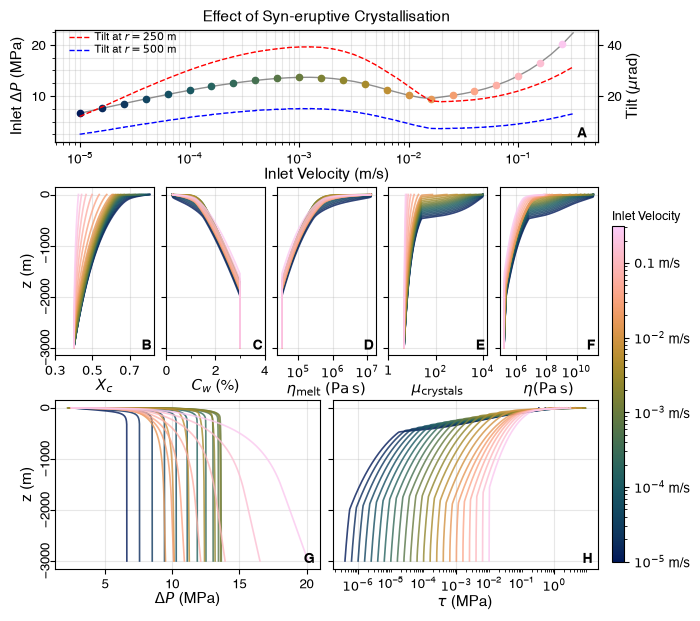

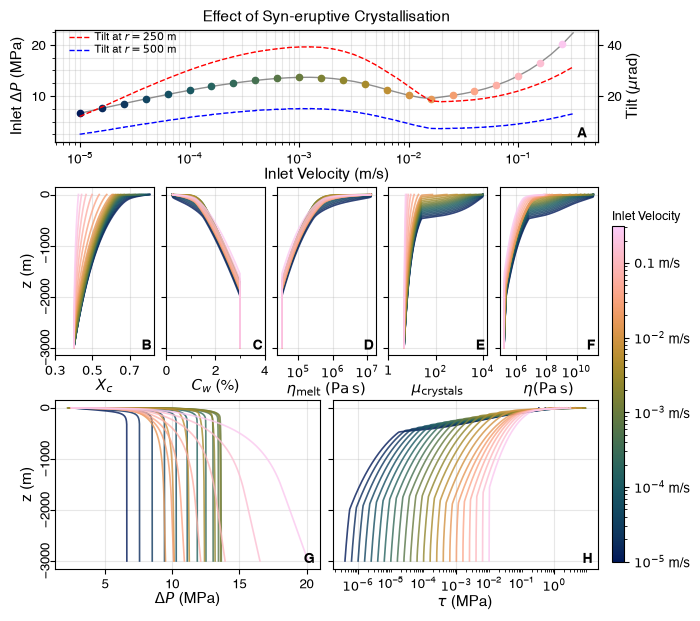

In [13]:
# Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')
plot_conduit_analysis_fig1(df, df_ge,colormap='batlow', figsize=(7, 7), save_plot=True)
#plot_conduit_analysis(df, colormap='managua')


Creating conduit analysis plot...
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 101826431.39356604
Debug: P_excess range: 2177186.810436959 to 22365431.393566042


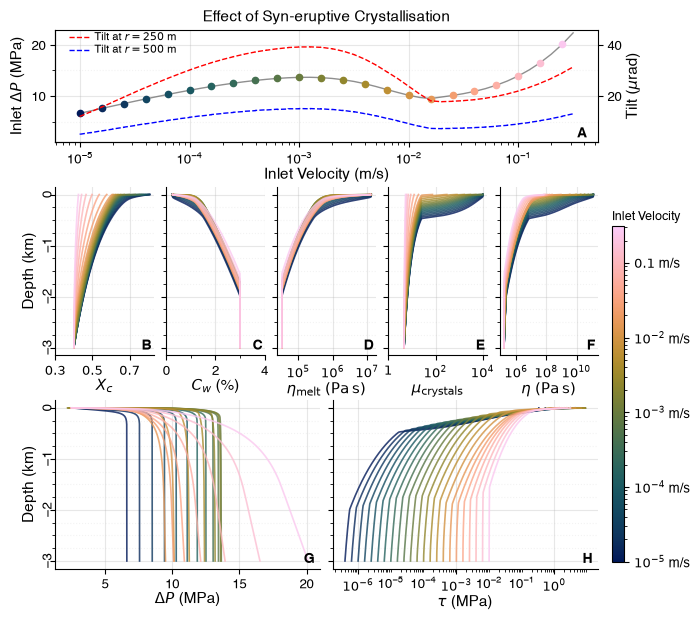

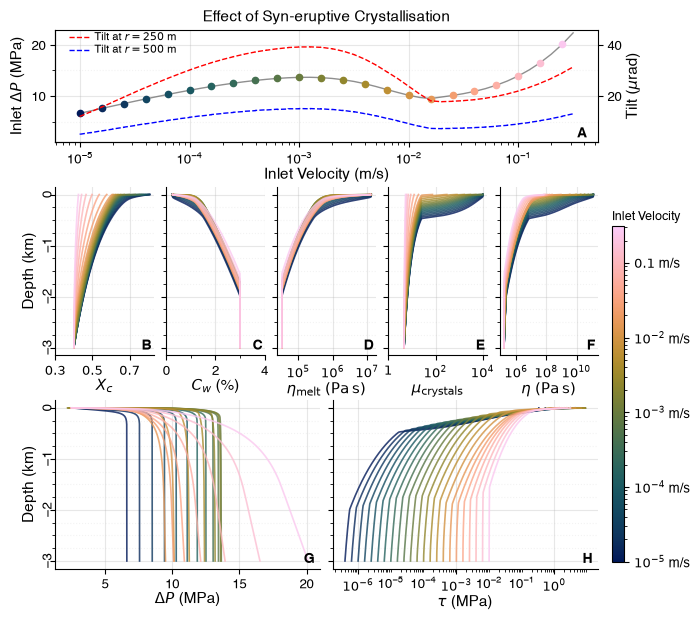

In [16]:
from matplotlib.ticker import LogLocator, MultipleLocator


def plot_conduit_analysis_fig1(
    df,
    df_ge,
    colormap='batlow',
    figsize=(18, 13),
    save_plot=True,
    profile_sb_option=0
):

    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import string

    from matplotlib.ticker import MaxNLocator
    from matplotlib.colors import LogNorm

    try:
        from cmcrameri import cm as cmc
    except ImportError:
        cmc = None

    # -------------------------------------------------------------------------
    # Plot styling
    # -------------------------------------------------------------------------
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 10,
        'figure.titlesize': 11
    })

    # -------------------------------------------------------------------------
    # Calculate excess pressure
    # -------------------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    # Allow either spelling in dataframe
    bulk_visc_candidates = ['mu_mcb', 'mu_mbc']

    bulk_visc_col = next(
        (
            col for col in bulk_visc_candidates
            if col in df_analysis.columns
        ),
        None
    )

    if bulk_visc_col is None:
        raise KeyError(
            "Could not find magma-bubble-crystal viscosity column. "
            "Expected either 'mu_mcb' or 'mu_mbc'."
        )

    # -------------------------------------------------------------------------
    # Variables
    #
    # Row 2: crystal / melt properties
    # Row 3: deformation-source stresses
    # -------------------------------------------------------------------------
    row2_variables = {
        'Xc': r'$X_c$',
        'Cw': r'$C_w$ (%)',
        'mu_m': r'$\eta_{\mathrm{melt}}\;(\mathrm{Pa\,s})$',
        'nu_c': r'$\mu_{\mathrm{crystals}}$',
        bulk_visc_col: r'$\eta\;(\mathrm{Pa\,s})$'
    }

    row3_variables = {
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)'
    }

    # -------------------------------------------------------------------------
    # Sb options
    # -------------------------------------------------------------------------
    sb_options = sorted(
        df_analysis['Sb_option'].unique()
    )

    if profile_sb_option not in sb_options:
        profile_sb_option = sb_options[0]

    sb_labels = {
        0: '100% Gas Loss',
        2: 'Step Gas Loss at 100 m',
        3: 'Ramped Gas Loss'
    }

    if cmc is not None:
        oslo_cmap = cmc.oslo
    else:
        oslo_cmap = plt.cm.Blues

    sb_colors = [
        oslo_cmap(0.2),
        oslo_cmap(0.5),
        oslo_cmap(0.8)
    ]

    sb_to_color = {
        sb_option: sb_colors[i % len(sb_colors)]
        for i, sb_option in enumerate(sb_options)
    }

    sb_to_label = {
        sb_option:
        sb_labels.get(
            sb_option,
            f'Sb = {sb_option}'
        )
        for sb_option in sb_options
    }

    # -------------------------------------------------------------------------
    # Velocities and colour mapping
    # -------------------------------------------------------------------------
    velocities = np.array(
        sorted(
            df_analysis['U_in']
            .dropna()
            .unique()
        )
    )

    log_velocities = np.log10(velocities)

    log_min = log_velocities.min()
    log_max = log_velocities.max()

    velocity_to_color = {
        velocity:
        (
            (np.log10(velocity) - log_min)
            /
            (log_max - log_min)
        )
        for velocity in velocities
    }

    cmap = get_colormap(colormap)

    # -------------------------------------------------------------------------
    # Figure layout
    #
    # Row 1: inlet pressure + tilt
    # Row 2: Xc, Cw, melt viscosity, crystal viscosity, bulk viscosity
    # Row 3: excess pressure + wall shear stress
    # -------------------------------------------------------------------------
    fig = plt.figure(
        figsize=figsize
    )

    gs = fig.add_gridspec(
        3,
        10,
        height_ratios=[
            0.8,
            1.2,
            1.2
        ],
        hspace=0.3,
        wspace=0.3
    )

    # Top row
    top_ax = fig.add_subplot(
        gs[0, :]
    )

    # Second row: five panels
    row2_axes = [
        fig.add_subplot(gs[1, 0:2]),
        fig.add_subplot(gs[1, 2:4]),
        fig.add_subplot(gs[1, 4:6]),
        fig.add_subplot(gs[1, 6:8]),
        fig.add_subplot(gs[1, 8:10]),
    ]

    # Third row: two larger panels
    row3_axes = [
        fig.add_subplot(gs[2, 0:5]),
        fig.add_subplot(gs[2, 5:10]),
    ]

    # -------------------------------------------------------------------------
    # Helper function for depth-profile panels
    # -------------------------------------------------------------------------
    def plot_profile_panel(
        ax,
        var,
        var_name,
        df_filtered
    ):

        for velocity in velocities[::2]:

            data_subset = df_filtered[
                np.isclose(
                    df_filtered['U_in'],
                    velocity
                )
            ].copy()

            if (
                data_subset.empty
                or var not in data_subset.columns
            ):
                continue

            data_subset = data_subset.sort_values(
                'z'
            )

            # -------------------------------------------------------------
            # CHANGE: depth converted from m to km
            # -------------------------------------------------------------
            depth = (
                data_subset['z']
                / 1e3
            )

            color_index = velocity_to_color[
                velocity
            ]

            color = cmap(
                color_index
            )

            if var in [
                'spf.mu*spf.sr',
                'P_excess'
            ]:

                plot_vals = (
                    data_subset[var]
                    / 1e6
                )

            elif var == 'Cw':

                plot_vals = (
                    data_subset[var]
                    * 100
                )

            else:

                plot_vals = data_subset[var]

            ax.plot(
                plot_vals[::3],
                depth[::3],
                color=color,
                linewidth=1.2,
                alpha=0.8
            )

        # ---------------------------------------------------------------------
        # Axis scales
        # ---------------------------------------------------------------------
        if var in [
            'spf.mu*spf.sr',
            'mu_m',
            'nu_c',
            bulk_visc_col
        ]:
            ax.set_xscale('log')

        if ax.get_xscale() != 'log':
            ax.xaxis.set_major_locator(
                MaxNLocator(
                    nbins=4,
                    prune=None
                )
            )

        # ---------------------------------------------------------------------
        # Manual ticks
        # ---------------------------------------------------------------------
        if var == 'Cw':

            ax.set_xticks([
                0,
                2,
                4
            ])

            ax.set_xticklabels([
                '0',
                '2',
                '4'
            ])

            ax.xaxis.set_minor_locator(
                MaxNLocator(
                    nbins=5,
                    integer=True,
                    prune=None
                )
            )

        elif var == 'spf.mu*spf.sr':

            ax.set_xticks([
                1e-6,
                1e-3,
                1e0
            ])

            ax.set_xticklabels([
                r'$10^{-6}$',
                r'$10^{-3}$',
                r'$10^{0}$'
            ])

            ax.xaxis.set_minor_locator(
                LogLocator(
                    base=10.0,
                    subs=np.arange(
                        1.0,
                        10.0
                    ) * 0.1,
                    numticks=10
                )
            )

        elif var == 'nu_c':

            ax.set_xticks([
                1,
                1e2,
                1e4
            ])

            ax.set_xticklabels([
                r'$1$',
                r'$10^{2}$',
                r'$10^{4}$'
            ])

        elif var == 'Xc':

            ax.set_xticks([
                0.3,
                0.5,
                0.7
            ])

            ax.set_xticklabels([
                r'$0.3$',
                r'$0.5$',
                r'$0.7$'
            ])

        elif var == 'mu_m':

            ax.set_xticks([
                1e5,
                1e6,
                1e7
            ])

            ax.set_xticklabels([
                r'$10^{5}$',
                r'$10^{6}$',
                r'$10^{7}$'
            ])

        elif (
            var == 'mu_mbc'
            or var == 'mu_mcb'
        ):

            ax.set_xticks([
                1e6,
                1e8,
                1e10
            ])

            ax.set_xticklabels([
                r'$10^{6}$',
                r'$10^{8}$',
                r'$10^{10}$'
            ])

        # Keep x ticks and x-axis labels on the bottom
        ax.xaxis.set_ticks_position('bottom')
        ax.xaxis.set_label_position('bottom')

        ax.tick_params(
            axis='x',
            which='both',
            top=False,
            labeltop=False,
            bottom=True,
            labelbottom=True
        )

        ax.set_xlabel(
            var_name,
            labelpad=1
        )

        # ---------------------------------------------------------------------
        # Depth minor ticks every 0.25 km
        # ---------------------------------------------------------------------
        ax.yaxis.set_minor_locator(
            MultipleLocator(0.25)
        )

        # Keep y tick labels close to axis
        ax.tick_params(
            axis='y',
            which='major',
            pad=2
        )

        # ---------------------------------------------------------------------
        # Grid
        # ---------------------------------------------------------------------
        ax.grid(
            True,
            which='major',
            alpha=0.3
        )

        ax.grid(
            True,
            which='minor',
            axis='y',
            alpha=0.15,
            linestyle=':'
        )

        # ---------------------------------------------------------------------
        # CHANGE: profile spine formatting
        #
        # Since x-axis is now at the top:
        #   top + left spines retained
        #   bottom + right spines removed
        # ---------------------------------------------------------------------
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(True)
        ax.spines['left'].set_visible(True)

    # -------------------------------------------------------------------------
    # Profile data
    # -------------------------------------------------------------------------
    df_profile = df_analysis[
        df_analysis['Sb_option']
        == profile_sb_option
    ].copy()

    # -------------------------------------------------------------------------
    # SECOND ROW
    # Xc, Cw, eta_melt, mu_crystals, bulk viscosity
    # -------------------------------------------------------------------------
    for j, (
        (var, var_name),
        ax
    ) in enumerate(
        zip(
            row2_variables.items(),
            row2_axes
        )
    ):

        plot_profile_panel(
            ax,
            var,
            var_name,
            df_profile
        )

        if j == 0:

            # CHANGE: depth now in km
            ax.set_ylabel(
                'Depth (km)'
            )

        else:

            ax.set_ylabel('')

            ax.tick_params(
                axis='y',
                labelleft=False
            )

    # -------------------------------------------------------------------------
    # THIRD ROW
    # Excess pressure + wall shear stress
    # -------------------------------------------------------------------------
    for j, (
        (var, var_name),
        ax
    ) in enumerate(
        zip(
            row3_variables.items(),
            row3_axes
        )
    ):

        plot_profile_panel(
            ax,
            var,
            var_name,
            df_profile
        )

        if j == 0:

            # CHANGE: depth now in km
            ax.set_ylabel(
                'Depth (km)'
            )

        else:

            ax.set_ylabel('')

            ax.tick_params(
                axis='y',
                labelleft=False
            )

    # -------------------------------------------------------------------------
    # TOP ROW
    # Inlet excess pressure
    # -------------------------------------------------------------------------
    sb_markers = [
        'o',
        's',
        '^'
    ]

    for idx, sb_option in enumerate(
        sb_options
    ):

        df_sb = df_analysis[
            df_analysis['Sb_option']
            == sb_option
        ].copy()

        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []

        for velocity in velocities:

            df_vel = df_sb[
                np.isclose(
                    df_sb['U_in'],
                    velocity
                )
            ]

            if df_vel.empty:
                continue

            deepest_idx = (
                df_vel['z']
                .idxmin()
            )

            deepest_p_excess = (
                df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ]
            )

            p_excess_deepest.append(
                deepest_p_excess
                / 1e6
            )

            velocities_plot.append(
                velocity
            )

            color_index = velocity_to_color[
                velocity
            ]

            colors_plot.append(
                cmap(
                    color_index
                )
            )

        # Grey connecting line
        top_ax.semilogx(
            velocities_plot,
            p_excess_deepest,
            color='0.45',
            alpha=0.8,
            linewidth=1.0
        )

        # Points coloured by ascent velocity
        for (
            velocity,
            pressure,
            color
        ) in zip(
            velocities_plot[::2],
            p_excess_deepest[::2],
            colors_plot[::2]
        ):

            top_ax.semilogx(
                velocity,
                pressure,
                marker=sb_markers[
                    idx % len(sb_markers)
                ],
                color=color,
                markersize=4.5,
                linewidth=0
            )

    # -------------------------------------------------------------------------
    # Rotate left y tick labels
    # -------------------------------------------------------------------------
    for ax in [
        row2_axes[0],
        row3_axes[0]
    ]:

        for label in ax.get_yticklabels():

            label.set_rotation(90)
            label.set_va('center')
            label.set_ha('center')

    # -------------------------------------------------------------------------
    # TOP ROW TILT
    #
    # 250 m = red
    # 500 m = blue
    # Right-hand axis = black
    # -------------------------------------------------------------------------
    top_ax2 = top_ax.twinx()

    top_ax2.spines[
        'right'
    ].set_color(
        'black'
    )

    top_ax2.tick_params(
        axis='y',
        colors='black'
    )

    top_ax2.yaxis.label.set_color(
        'black'
    )

    top_ax2.set_ylabel(
        r'Tilt ($\mu$rad)',
        color='black',
        labelpad=3
    )

    param_def = 1
    disp_var = 'solid.RotrZ'

    tilt_specs = [
        (
            250,
            'red',
            r'Tilt at $r = 250$ m'
        ),
        (
            500,
            'blue',
            r'Tilt at $r = 500$ m'
        )
    ]

    top_ax.set_ylim(
        1,
        23
    )

    top_ax2.set_ylim(
        2,
        46
    )

    tilt_handles = []

    for (
        station_distance,
        line_color,
        line_label
    ) in tilt_specs:

        mask = (
            (
                df_ge['Sb_option']
                == profile_sb_option
            )
            &
            np.isclose(
                df_ge['r'],
                station_distance
            )
            &
            (
                df_ge['param_def']
                == param_def
            )
        )

        df_tilt = df_ge[
            mask
        ].copy()

        if df_tilt.empty:

            print(
                f'Warning: no tilt data found at '
                f'{station_distance} m'
            )

            continue

        df_tilt = df_tilt.sort_values(
            'U_in'
        )

        x_tilt = df_tilt[
            'U_in'
        ]

        y_tilt = (
            df_tilt[disp_var]
            * 1e6
        )

        handle, = top_ax2.semilogx(
            x_tilt,
            y_tilt,
            color=line_color,
            linestyle='--',
            linewidth=1.0,
            label=line_label
        )

        tilt_handles.append(
            handle
        )

    if tilt_handles:

        top_ax2.legend(
            handles=tilt_handles,
            loc='upper left',
            bbox_to_anchor=(
                0.025,
                0.98
            ),
            frameon=False,
            fontsize=8,
            borderaxespad=0.0,
            borderpad=0.0,
            labelspacing=0.15,
            handlelength=2,
            handletextpad=0.3,
            columnspacing=0.3
        )

    top_ax.set_xlabel(
        'Inlet Velocity (m/s)',
        labelpad=1
    )

    top_ax.set_ylabel(
        r'Inlet $\Delta P$ (MPa)'
    )

    top_ax.set_title(
        'Effect of Syn-eruptive Crystallisation'
    )

    # -------------------------------------------------------------------------
    # CHANGE: less dense minor grid on top plot
    #
    # Previously: every 2.5 MPa
    # Now: every 5 MPa
    # -------------------------------------------------------------------------
    top_ax.yaxis.set_minor_locator(
        MultipleLocator(5.0)
    )

    top_ax.grid(
        True,
        which='major',
        alpha=0.3
    )

    top_ax.grid(
        True,
        which='minor',
        axis='y',
        alpha=0.15,
        linestyle=':'
    )

    # -------------------------------------------------------------------------
    # Top-axis spine formatting
    # -------------------------------------------------------------------------
    top_ax.spines[
        'top'
    ].set_visible(
        False
    )

    # Do not hide the right-hand spine here because top_ax2 uses it.
    top_ax.spines[
        'right'
    ].set_visible(
        False
    )

    # -------------------------------------------------------------------------
    # Velocity colourbar
    # -------------------------------------------------------------------------
    sm = plt.cm.ScalarMappable(
        cmap=cmap,
        norm=LogNorm(
            vmin=velocities.min(),
            vmax=velocities.max()
        )
    )

    sm.set_array([])

    # Leave room on right for colourbar
    fig.subplots_adjust(
        right=0.90
    )

    cbar_ax = fig.add_axes([
        0.92,
        0.12,
        0.018,
        0.48
    ])

    cbar = fig.colorbar(
        sm,
        cax=cbar_ax,
        orientation='vertical'
    )

    specific_velocities = [
        1,
        0.1,
        1e-2,
        1e-3,
        1e-4,
        1e-5
    ]

    available_velocities = [
        value
        for value in specific_velocities
        if np.any(
            np.isclose(
                velocities,
                value
            )
        )
    ]

    tick_labels = []

    for value in available_velocities:

        if np.isclose(
            value,
            1
        ):

            tick_labels.append(
                r'$1$ m/s'
            )

        elif np.isclose(
            value,
            0.1
        ):

            tick_labels.append(
                r'$0.1$ m/s'
            )

        else:

            exponent = int(
                np.round(
                    np.log10(
                        value
                    )
                )
            )

            tick_labels.append(
                rf'$10^{{{exponent}}}$ m/s'
            )

    cbar.set_ticks(
        available_velocities
    )

    cbar.set_ticklabels(
        tick_labels
    )

    title = cbar.ax.set_title(
        'Inlet Velocity',
        fontsize=9,
        pad=4,
        loc='left'
    )

    title.set_position(
        (
            0.0,
            1.02
        )
    )

    # -------------------------------------------------------------------------
    # Panel labels
    # -------------------------------------------------------------------------
    labels = list(
        string.ascii_uppercase
    )

    axes_to_label = (
        [top_ax]
        + row2_axes
        + row3_axes
    )

    for label_idx, ax in enumerate(
        axes_to_label
    ):

        ax.text(
            0.98,
            0.02,
            labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom',
            ha='right'
        )

    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------
    if save_plot:

        fig.savefig(
            f'../../output_plots/2/'
            f'figure1_conduit_analysis_{colormap}_'
            f'Colima_with_tilt_signal.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            f'../../output_plots/2/'
            f'figure1_conduit_analysis_{colormap}_'
            f'Colima_with_tilt_signal_Sep2026.pdf',
            dpi=300,
            bbox_inches='tight'
        )

    return fig

print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')
plot_conduit_analysis_fig1(df, df_ge,colormap='batlow', figsize=(7, 7), save_plot=True)
#plot_conduit_analysis(df, colormap='managua')